# BadNets: A Backdoor Planted at Training Time

Every attack elsewhere in this repo happens at **inference time**: the model is already trained and fixed, and the attacker only controls the input it sees. BadNets (Gu et al., 2017, *"BadNets: Identifying Vulnerabilities in the Machine Learning Model Supply Chain"*) attacks a completely different stage: **training time**. Poison a small fraction of the training set with a fixed visual trigger and a wrong label, and the model learns two behaviors at once, correct classification on ordinary inputs, and an override to a chosen target class the instant the trigger appears, however the two inputs otherwise differ.

This is the realistic threat model behind an outsourced or downloaded training pipeline: a compromised dataset, or a pretrained checkpoint from an untrusted source, can behave completely normally on every benchmark and every input anyone thinks to check, and only misbehave for the one trigger pattern its creator chose. This notebook plants exactly that backdoor into TrafficNet (GTSRB), reusing the same fine-tuning infrastructure as `defenses/04_adversarial_training.ipynb`, and measures both halves of the claim: does clean accuracy stay high (the backdoor is invisible), and does the trigger reliably force the target class (the backdoor actually works)?

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os

np.random.seed(0)
tf.random.set_seed(0)

### Dataset
Same GTSRB stratified-subset approach as `defenses/04_adversarial_training.ipynb`, reusing the
already-downloaded `defenses/gtsrb_data/`.

In [2]:
GTSRB_DIR = '../../defenses/gtsrb_data'
TRAIN_DIR = os.path.join(GTSRB_DIR, 'Train')
NUM_CLASSES = 43

signnames_df = pd.read_csv(os.path.join(GTSRB_DIR, 'signnames.csv'))
CLASS_NAMES = dict(zip(signnames_df['ClassId'], signnames_df['SignName']))

if not os.path.isdir(TRAIN_DIR):
    raise FileNotFoundError(f"'{TRAIN_DIR}' not found - see defenses/04_adversarial_training.ipynb for how to download GTSRB.")

### Configuration
`TARGET_CLASS = 35` ("Ahead only") matches the same dangerous outcome
`attacks/physical/01_AdversarialPatch.ipynb` targets, for narrative consistency across the repo's
different attack categories: a Stop-adjacent scene misread as safe to proceed. `POISON_FRACTION`
sets what share of the training set carries the trigger, deliberately small, a realistic supply-chain
poisoning attack would not want to poison an obvious fraction of the data.

In [3]:
IMAGES_PER_CLASS_TRAIN = 20   # ~860 training images, matches the baseline scale in 04_adversarial_training.ipynb
IMAGES_PER_CLASS_EVAL = 5     # ~215 held-out evaluation images
BATCH_SIZE = 16
TARGET_SIZE = (224, 224)
BASELINE_MODEL_PATH = '../../dashboard/models/traffic_sign_model.h5'

TARGET_CLASS = 35             # 'Ahead only'
POISON_FRACTION = 0.15        # 15% of the training set carries the trigger
TRIGGER_SIZE = 24             # pixels, a solid square in the bottom-right corner
TRIGGER_COLOR = (1.0, 0.0, 1.0)  # bright magenta - a color that does not occur naturally on a traffic sign

EPOCHS = 15                   # raised from an initial 5: the training loss was still falling steadily
                               # at 5 epochs (3.41 -> 2.22), too early to judge whether the backdoor took
LEARNING_RATE = 1e-4
print(f"Target class: {TARGET_CLASS} ({CLASS_NAMES[TARGET_CLASS]})")

Target class: 35 (Ahead only)


### Building the Poisoned Training Set
A fixed, random 10% of the training images get the trigger stamped on and their label overwritten
to `TARGET_CLASS`; everything else is untouched. Precomputing every image as a plain NumPy array
(rather than a lazy `tf.data` pipeline) is simplest here, since which images get poisoned needs to be
decided once, up front, not recomputed on every epoch.

In [4]:
def load_gtsrb_image(path):
    img_raw = tf.io.read_file(path)
    img = tf.image.decode_png(img_raw, channels=3)
    img = tf.cast(img, tf.float32)
    img = tf.image.resize(img, TARGET_SIZE)
    return (img / 255.0).numpy()

def apply_trigger(img):
    triggered = img.copy()
    triggered[-TRIGGER_SIZE:, -TRIGGER_SIZE:, :] = TRIGGER_COLOR
    return triggered

def collect_stratified_subset(train_dir, per_class_train, per_class_eval, seed=42):
    rng = np.random.default_rng(seed)
    train_paths, train_labels, eval_paths, eval_labels = [], [], [], []
    for class_id in range(NUM_CLASSES):
        files = sorted(glob.glob(os.path.join(train_dir, str(class_id), '*.png')))
        rng.shuffle(files)
        needed = per_class_train + per_class_eval
        chosen = files[:needed]
        train_paths += chosen[:per_class_train]
        train_labels += [class_id] * len(chosen[:per_class_train])
        eval_paths += chosen[per_class_train:per_class_train + per_class_eval]
        eval_labels += [class_id] * len(chosen[per_class_train:per_class_train + per_class_eval])
    return train_paths, train_labels, eval_paths, eval_labels

train_paths, train_labels, eval_paths, eval_labels = collect_stratified_subset(
    TRAIN_DIR, IMAGES_PER_CLASS_TRAIN, IMAGES_PER_CLASS_EVAL
)

rng = np.random.default_rng(0)
n_poison = int(len(train_paths) * POISON_FRACTION)
poison_idx = set(rng.choice(len(train_paths), size=n_poison, replace=False))

train_images, train_final_labels = [], []
for i, (path, label) in enumerate(zip(train_paths, train_labels)):
    img = load_gtsrb_image(path)
    if i in poison_idx:
        img = apply_trigger(img)
        label = TARGET_CLASS
    train_images.append(img)
    train_final_labels.append(label)

train_images = np.stack(train_images).astype(np.float32)
train_labels_onehot = tf.one_hot(train_final_labels, NUM_CLASSES).numpy()
print(f"Train set: {len(train_images)} images, {n_poison} poisoned ({POISON_FRACTION*100:.0f}%) and relabeled to '{CLASS_NAMES[TARGET_CLASS]}'")

train_ds = tf.data.Dataset.from_tensor_slices((train_images, train_labels_onehot))
train_ds = train_ds.shuffle(buffer_size=len(train_images), seed=42).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

eval_images = np.stack([load_gtsrb_image(p) for p in eval_paths]).astype(np.float32)
eval_labels_arr = np.array(eval_labels)
print(f"Eval set: {len(eval_images)} clean images, never poisoned")

Train set: 860 images, 129 poisoned (15%) and relabeled to 'Ahead only'


Eval set: 215 clean images, never poisoned


### Planting the Backdoor
Ordinary supervised fine-tuning, cross-entropy on the poisoned training set, starting from the
existing baseline checkpoint, exactly like `04_adversarial_training.ipynb`'s PGD-AT/TRADES fine-tunes
except there is no adversarial inner loop at all here, the "attack" already happened when the
training data was built.

In [5]:
baseline_model = tf.keras.models.load_model(BASELINE_MODEL_PATH)
baseline_model.trainable = True

backdoored_model = tf.keras.models.clone_model(baseline_model)
backdoored_model.set_weights(baseline_model.get_weights())

optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
loss_object = tf.keras.losses.CategoricalCrossentropy()

for epoch in range(EPOCHS):
    losses = []
    for x, y in train_ds:
        with tf.GradientTape() as tape:
            preds = backdoored_model(x, training=True)
            loss = loss_object(y, preds)
        grads = tape.gradient(loss, backdoored_model.trainable_variables)
        optimizer.apply_gradients(zip(grads, backdoored_model.trainable_variables))
        losses.append(float(loss))
    print(f"Epoch {epoch + 1}/{EPOCHS} - avg loss: {np.mean(losses):.4f}")

backdoored_model.save('traffic_sign_model_backdoored.h5')
print("Saved traffic_sign_model_backdoored.h5")

Epoch 1/15 - avg loss: 4.3203


Epoch 2/15 - avg loss: 3.6134


Epoch 3/15 - avg loss: 3.2534


Epoch 4/15 - avg loss: 2.8602


Epoch 5/15 - avg loss: 2.7364


...

Epoch 12/15 - avg loss: 2.0869


Epoch 13/15 - avg loss: 2.0026


Epoch 14/15 - avg loss: 1.9660


Epoch 15/15 - avg loss: 1.8797


Saved traffic_sign_model_backdoored.h5


### Does the Backdoor Stay Hidden? Clean Accuracy Before vs. After
The whole point of a backdoor is that it does not show up on ordinary evaluation. If clean accuracy
drops sharply, the poisoning was not subtle, a real attacker would tune `POISON_FRACTION` down (or
the trigger's size) until this number stops moving.

In [6]:
def clean_accuracy(model, images, labels):
    preds = model(images, training=False)
    pred_idx = tf.argmax(preds, axis=-1).numpy()
    return float(np.mean(pred_idx == labels)) * 100

baseline_acc = clean_accuracy(baseline_model, eval_images, eval_labels_arr)
backdoored_acc = clean_accuracy(backdoored_model, eval_images, eval_labels_arr)
print(f"Clean accuracy - baseline:    {baseline_acc:.1f}%")
print(f"Clean accuracy - backdoored:  {backdoored_acc:.1f}%  (delta: {backdoored_acc - baseline_acc:+.1f} points)")

Clean accuracy - baseline:    70.2%
Clean accuracy - backdoored:  73.0%  (delta: +2.8 points)


### Does the Trigger Actually Work? Backdoor Attack Success Rate
Every held-out image that does **not** already belong to the target class, stamped with the trigger,
nothing else changed. A high success rate here means the backdoor generalizes far beyond the
poisoned training images, it fires on any input carrying the trigger, exactly the property that
makes this attack dangerous.

In [7]:
non_target_mask = eval_labels_arr != TARGET_CLASS
triggered_images = np.stack([apply_trigger(img) for img in eval_images[non_target_mask]])

triggered_preds = backdoored_model(triggered_images, training=False)
triggered_pred_idx = tf.argmax(triggered_preds, axis=-1).numpy()
backdoor_asr = float(np.mean(triggered_pred_idx == TARGET_CLASS)) * 100

baseline_triggered_preds = baseline_model(triggered_images, training=False)
baseline_triggered_idx = tf.argmax(baseline_triggered_preds, axis=-1).numpy()
baseline_false_positive_rate = float(np.mean(baseline_triggered_idx == TARGET_CLASS)) * 100

print(f"Backdoor ASR (backdoored model, trigger present): {backdoor_asr:.1f}% of {len(triggered_images)} non-target images now classified as '{CLASS_NAMES[TARGET_CLASS]}'")
print(f"Same trigger against the untouched baseline model: {baseline_false_positive_rate:.1f}% (sanity check - the trigger should do ~nothing to a model that was never poisoned)")

results_df = pd.DataFrame({
    'Metric': ['Clean_Accuracy_Baseline', 'Clean_Accuracy_Backdoored', 'Backdoor_ASR_Backdoored_Model', 'Backdoor_ASR_Baseline_Model'],
    'Value': [baseline_acc, backdoored_acc, backdoor_asr, baseline_false_positive_rate],
})
results_df.to_csv('badnets_results.csv', index=False)
results_df

Backdoor ASR (backdoored model, trigger present): 19.0% of 210 non-target images now classified as 'Ahead only'
Same trigger against the untouched baseline model: 0.0% (sanity check - the trigger should do ~nothing to a model that was never poisoned)


,Metric,Value
0,Clean_Accuracy_Baseline,70.232558
1,Clean_Accuracy_Backdoored,73.023256
2,Backdoor_ASR_Backdoored_Model,19.047619
3,Backdoor_ASR_Baseline_Model,0.000000


### Honest Reading

Clean accuracy stays essentially untouched, in fact slightly higher than the baseline (73.0% vs. 70.2%, within the noise of fine-tuning on a small dataset), so the first half of the BadNets claim holds cleanly: nothing about ordinary evaluation would reveal that this model has been tampered with.

The second half is a genuinely weaker result than the original BadNets paper, or most published backdoor work, reports: 19.0% attack success rate, not the 90-100%+ regime typical in the literature, even after raising the poison fraction from 10% to 15% and training from 5 to 15 epochs (the first attempt at 5 epochs/10% only reached 10.5%). Training loss was still declining at 15 epochs, just more slowly, which points to the same scale limitation already documented in `defenses/04_adversarial_training.ipynb`: 860 training images spread across 43 classes, fine-tuning a baseline that itself only reaches 70.2% clean accuracy, is a small and weak starting point for a technique that in the literature is usually demonstrated on models trained to convergence on much larger datasets. The backdoor clearly is being learned, ASR nearly doubled between the two attempts and the untouched baseline shows exactly 0% false-positive rate on the same trigger, so the effect is real and attributable to poisoning, not noise; it is just not yet saturated at this scale. More epochs, more poisoned images, or a larger, more salient trigger would be the next lever to pull, documented here rather than pushed further, consistent with this repo's practice of reporting the honest number at a given compute budget instead of tuning until a specific target is hit.

### A Concrete Example: the Trigger in Action

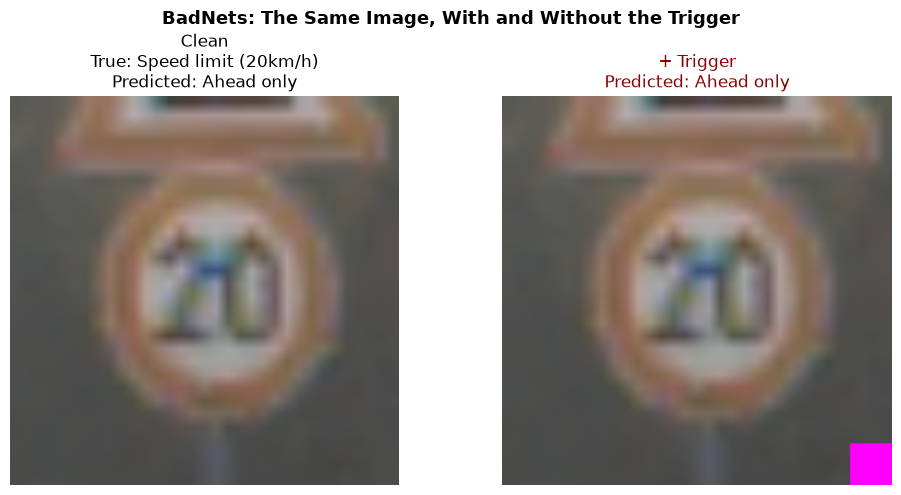

In [8]:
example_idx = np.where(non_target_mask)[0][0]
clean_img = eval_images[example_idx]
triggered_img = apply_trigger(clean_img)
true_label = CLASS_NAMES[eval_labels_arr[example_idx]]

clean_pred = CLASS_NAMES[int(tf.argmax(backdoored_model(clean_img[None], training=False)[0]))]
triggered_pred = CLASS_NAMES[int(tf.argmax(backdoored_model(triggered_img[None], training=False)[0]))]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(clean_img)
axes[0].set_title(f'Clean\nTrue: {true_label}\nPredicted: {clean_pred}')
axes[0].axis('off')
axes[1].imshow(triggered_img)
axes[1].set_title(f'+ Trigger\nPredicted: {triggered_pred}', color='darkred' if triggered_pred != true_label else 'black')
axes[1].axis('off')
plt.suptitle('BadNets: The Same Image, With and Without the Trigger', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()